# 02 — Data Harmonization: Dataset Training Terpadu Way2Home

Notebook ini membangun **satu dataset final** `data/final/way2home_kendala_training.csv` beserta subset training per tugas ML untuk fitur *AI Analisis Kendala* Way2Home.

**Alur kerja (sesuai brief):**
1. Load semua dataset → 2. Audit struktur & granularitas → 3. Mapping kolom → 4. Harmonisasi → 5. Cleaning & transformasi → 6. Feature engineering → 7. Pembentukan target → 8. Integrasi → 9. Subset training → 10. Validasi & penyimpanan.

**Prinsip yang dipegang:**
- Unit observasi final = **project-level**. Satu baris = satu proyek konstruksi beserta kendala/kondisi yang tercatat.
- Data survei (Aceh) **tidak** diubah menjadi label kejadian. Data ini disimpan sebagai data pendukung terpisah (bobot faktor per kategori).
- Tidak ada nilai, baris, maupun target yang dikarang. Kolom tanpa padanan dibiarkan `null`.
- Kolom pelacakan (`source_dataset`, `source_record_id`, `data_granularity`, `is_synthetic`, `project_group_id`) **bukan fitur**.
- Keputusan yang tidak bisa dibuat secara valid ditandai **UNRESOLVED**.

Dasar keputusan: audit Tahap 1 (`01_dataset_exploration.ipynb`, `reports/00_dataset_audit.md`).

## 0. Setup: path relatif dari root project & utilitas

In [1]:
import io, json, zipfile, shutil, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import kstest
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.model_selection import cross_val_score, StratifiedKFold, KFold

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 80); pd.set_option("display.max_colwidth", 70)
SEED = 42

def find_project_root(start: Path = Path.cwd()) -> Path:
    # Cari ke atas sampai menemukan folder data/raw, supaya notebook bisa dijalankan dari root maupun notebooks/
    for p in [start, *start.parents]:
        if (p / "data" / "raw").is_dir():
            return p
    raise FileNotFoundError("Folder data/raw tidak ditemukan. Jalankan notebook di dalam folder project.")

ROOT = find_project_root()
RAW, PROC, FINAL, INTERIM = ROOT/"data/raw", ROOT/"data/processed", ROOT/"data/final", ROOT/"data/interim"
REPORTS = ROOT/"reports"
for d in (PROC, FINAL, INTERIM, REPORTS):
    d.mkdir(parents=True, exist_ok=True)

# Palet grafik (satu hue biru; ramp biru untuk kelas ordinal)
C_MAIN = "#2a78d6"
C_ORD = {"LOW": "#86b6ef", "MEDIUM": "#3987e5", "HIGH": "#184f95"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e5e5e5", "axes.axisbelow": True})
print("Project root:", ROOT)

Project root: /home/claude/way2home


## 1. Load seluruh dataset

Loader bersifat generik:
- Semua file di `data/raw/` dibaca (termasuk subfolder). ZIP diekstrak ke `data/interim/unzipped/`.
- **CSV** dibaca langsung.
- **XLSX/XLS**: semua sheet diperiksa. Sheet yang ternyata berisi teks CSV di satu kolom diurai ulang. Header dideteksi otomatis, sehingga tidak bergantung pada posisi baris.
- Workbook sangat besar (>20 MB) hanya dicatat metadatanya (sheet, dimensi) agar memori aman. Isinya dinilai lewat identifikasi sumber.
- File non-tabel (PDF, RTF, IPYNB, skrip) dicatat sebagai dokumentasi.

Nama file **tidak** dipakai untuk menentukan sumber. Sumber diidentifikasi dari **signature kolom** (Langkah 2).

In [2]:
DOC_EXT = {".pdf", ".rtf", ".ipynb", ".txt", ".md", ".py"}
LARGE_XLSX_BYTES = 20 * 1024 * 1024

def iter_raw_files(raw_dir: Path):
    # Yield semua file; isi ZIP diekstrak dulu lalu ikut di-yield
    for path in sorted(raw_dir.rglob("*")):
        if not path.is_file():
            continue
        if path.suffix.lower() == ".zip":
            target = INTERIM / "unzipped" / path.stem
            if target.exists():
                shutil.rmtree(target)
            with zipfile.ZipFile(path) as zf:
                zf.extractall(target)
            yield from (p for p in sorted(target.rglob("*")) if p.is_file())
        else:
            yield path

def _looks_like_csv_in_one_column(raw: pd.DataFrame) -> bool:
    nonempty = raw.dropna(how="all", axis=1)
    return nonempty.shape[1] == 1 and nonempty.iloc[:, 0].astype(str).head(5).str.count(",").min() >= 2

def _table_from_sheet(raw: pd.DataFrame) -> pd.DataFrame:
    # Deteksi header: baris pertama yang terisi >= 50% kolom. Header kosong diisi dari teks terdekat di atasnya.
    raw = raw.dropna(how="all").dropna(how="all", axis=1).reset_index(drop=True)
    raw.columns = range(raw.shape[1])
    fill = raw.notna().sum(axis=1)
    h = int(np.argmax(fill.values >= 0.5 * raw.shape[1]))
    names = []
    for j in range(raw.shape[1]):
        v = raw.iat[h, j]
        if pd.isna(v):
            above = raw.iloc[:h, j].dropna()
            v = str(above.iloc[-1]).strip(" .") if len(above) else f"col_{j}"
        names.append(str(v).strip())
    body = raw.iloc[h + 1:].reset_index(drop=True)
    body.columns = names
    return body.dropna(how="all")

def load_all(raw_dir: Path):
    tables, docs = [], []
    for path in iter_raw_files(raw_dir):
        rel, ext = str(path.relative_to(ROOT)), path.suffix.lower()
        if ext == ".csv":
            tables.append({"file": rel, "sheet": None, "df": pd.read_csv(path), "note": "csv"})
        elif ext in (".xlsx", ".xls"):
            if path.stat().st_size > LARGE_XLSX_BYTES:
                import openpyxl
                wb = openpyxl.load_workbook(path, read_only=True)
                meta = pd.DataFrame([{"sheet": ws.title, "rows": ws.max_row, "cols": ws.max_column} for ws in wb.worksheets])
                header = {ws.title: [c for c in next(ws.iter_rows(min_row=1, max_row=1, values_only=True)) if c is not None][:40]
                          for ws in wb.worksheets}
                wb.close()
                tables.append({"file": rel, "sheet": "*", "df": None, "meta": meta, "headers": header,
                               "note": "workbook besar: metadata saja"})
                continue
            for sheet, raw in pd.read_excel(path, sheet_name=None, header=None).items():
                if _looks_like_csv_in_one_column(raw):
                    text = "\n".join(raw.dropna(how="all", axis=1).iloc[:, 0].dropna().astype(str))
                    tables.append({"file": rel, "sheet": sheet, "df": pd.read_csv(io.StringIO(text)), "note": "csv di dalam xlsx"})
                else:
                    tables.append({"file": rel, "sheet": sheet, "df": _table_from_sheet(raw), "note": "xlsx (header terdeteksi)"})
        elif ext in DOC_EXT or path.name.endswith(".py.txt"):
            docs.append({"file": rel, "type": ext or "text", "size_KB": round(path.stat().st_size / 1024, 1)})
        else:
            docs.append({"file": rel, "type": f"tidak dikenal ({ext})", "size_KB": round(path.stat().st_size / 1024, 1)})
    return tables, docs

tables, docs = load_all(RAW)
print(f"Tabel terbaca: {len(tables)} | file dokumentasi: {len(docs)}")
display(pd.DataFrame([{"file": t["file"], "sheet": t["sheet"], "note": t["note"],
                       "shape": None if t["df"] is None else t["df"].shape} for t in tables]))
display(pd.DataFrame(docs))

Tabel terbaca: 8 | file dokumentasi: 5
                                                         file                            sheet                           note        shape
0                                     data/raw/Dataset_1.xlsx                   Rekap Bagian B       xlsx (header terdeteksi)     (68, 65)
1                   data/raw/RCPLIB__Parameters_and_BKS_.xlsx                                *  workbook besar: metadata saja         None
2               data/raw/bim_ai_civil_engineering_dataset.csv                              NaN                            csv   (1000, 28)
3                          data/raw/construction_projects.csv                              NaN                            csv   (5000, 12)
4  data/raw/project_delay_cost_overrun_summary_final.csv.xlsx  project_delay_cost_overrun_summ              csv di dalam xlsx    (4000, 7)
5                       data/raw/project_risk_raw_dataset.csv                              NaN                            csv  

## 2. Audit struktur & granularitas (identifikasi sumber dari signature kolom)

In [3]:
# Signature = himpunan kolom yang khas untuk tiap sumber (bukan nama file)
SIGNATURES = [
    ("CONSTRUCTION_DELAY_RISK_GH", {"delay_risk", "material_delay_days", "weather_delay_days", "delay_days"}),
    ("CONSTRUCTION_DELAY_PRED_ALG", {"Delay_Risk", "Supplier_Delay", "Material_Availability", "Budget_Million_DZD"}),
    ("BIM_AI_CIVIL", {"Safety_Risk_Score", "Crack_Width", "Anomaly_Detected", "Risk_Level"}),
    ("SIM_PROJECT_RISK_RAW", {"Risk_Level", "Team_Turnover_Rate", "Project_Budget_USD", "Estimated_Timeline_Months"}),
    ("SIM_EV_SUMMARY", {"Schedule_Delay", "Cost_Overrun", "Planned_Budget", "Actual_Duration_Months"}),
    ("SIM_EV_TIMESERIES", {"CPI_Monthly", "SPI_Monthly", "PV", "EV", "AC"}),
    ("ACEH_DELAY_SURVEY", {"X1.1", "X10.7", "Y1"}),
]

def identify_source(t):
    if t["df"] is None:
        sheets = set(t["meta"]["sheet"])
        hdr = set(sum(t["headers"].values(), []))
        if {"#Act", "CNC", "RF", "RU"} <= hdr:
            return "RCPLIB_BENCHMARK"
        return "UNKNOWN"
    cols = set(map(str, t["df"].columns))
    for name, sig in SIGNATURES:
        if sig <= cols:
            return name
    return "UNKNOWN"

for t in tables:
    t["source"] = identify_source(t)
src = {t["source"]: t for t in tables}
assert "UNKNOWN" not in src, "Ada tabel yang tidak dikenali — periksa SIGNATURES"

# Metadata sumber: granularitas & status sintetis berdasarkan dokumentasi + bukti audit Tahap 1
SOURCE_META = {
 "ACEH_DELAY_SURVEY": dict(title="Causes of Delays in Construction Projects — Aceh (Mendeley 10.17632/2wckhrzz5j.1)",
     granularity="survey", is_synthetic=False,
     evidence="Data survei 68 manajer proyek (Rauzana & Dharma 2022, PLOS ONE)"),
 "SIM_PROJECT_RISK_RAW": dict(title="Simulated Project Risk & Earned-Value — fitur mentah (Mendeley)",
     granularity="project", is_synthetic=True, evidence="Dinyatakan simulated oleh sumber"),
 "SIM_EV_SUMMARY": dict(title="Simulated Project Risk & Earned-Value — ringkasan delay/cost",
     granularity="project", is_synthetic=True, evidence="Dihasilkan simulate_project_ev_metrics.py dari SIM_PROJECT_RISK_RAW"),
 "SIM_EV_TIMESERIES": dict(title="Simulated Project Risk & Earned-Value — deret waktu bulanan",
     granularity="project-month", is_synthetic=True, evidence="Dihasilkan simulate_project_ev_metrics.py"),
 "CONSTRUCTION_DELAY_RISK_GH": dict(title="Construction Project Delay Risk Prediction (GitHub)",
     granularity="project", is_synthetic=True,
     evidence="Tanpa dokumentasi asal; durasi terdistribusi seragam (uji KS), label = ambang delay_days"),
 "BIM_AI_CIVIL": dict(title="BIM AI Civil Engineering Dataset (GitHub)", granularity="project", is_synthetic=True,
     evidence="Rasio biaya/durasi seragam & independen; tanggal tidak konsisten; Start_Date +1 hari per baris"),
 "CONSTRUCTION_DELAY_PRED_ALG": dict(title="Construction Delay Prediction (GitHub, synthetic — Aljazair)",
     granularity="project", is_synthetic=True, evidence="Dinyatakan synthetic oleh nama file/sumber"),
 "RCPLIB_BENCHMARK": dict(title="RCPLIB — Resource-Constrained Project Library (diunggah sebagai pengganti DSLIB/PSLIB)",
     granularity="scheduling-instance", is_synthetic=True, evidence="Instance buatan generator untuk benchmark RCPSP"),
}

rows = []
for name, t in src.items():
    df = t["df"]
    n = int(t["meta"].query("sheet == 'All'")["rows"].iloc[0]) - 1 if df is None else len(df)
    rows.append({"source_dataset": name, "file": t["file"], "sheet": t["sheet"], "n_records_raw": n,
                 "n_cols": int(t["meta"].query("sheet == 'All'")["cols"].iloc[0]) if df is None else df.shape[1],
                 "granularity": SOURCE_META[name]["granularity"], "is_synthetic": SOURCE_META[name]["is_synthetic"],
                 "missing_cells": None if df is None else int(df.isna().sum().sum()),
                 "duplicate_rows": None if df is None else int(df.duplicated().sum())})
inventory = pd.DataFrame(rows).sort_values("source_dataset").reset_index(drop=True)
display(inventory)

                source_dataset                                                        file                            sheet  n_records_raw  n_cols          granularity  is_synthetic  missing_cells  duplicate_rows
0            ACEH_DELAY_SURVEY                                     data/raw/Dataset_1.xlsx                   Rekap Bagian B             68      65               survey         False            0.0             0.0
1                 BIM_AI_CIVIL               data/raw/bim_ai_civil_engineering_dataset.csv                              NaN           1000      28              project          True            0.0             0.0
2  CONSTRUCTION_DELAY_PRED_ALG                data/raw/synthetic_construction_projects.csv                              NaN           1000      15              project          True            0.0             0.0
3   CONSTRUCTION_DELAY_RISK_GH                          data/raw/construction_projects.csv                              NaN           5000      12  

### 2a. Keputusan integrasi per sumber

Tidak ada sumber yang berisi data **issue-level** (satu baris = satu kejadian kendala). Unit observasi yang dapat dibuat konsisten adalah **project-level**: satu proyek konstruksi dengan kendala dan kondisi yang tercatat beserta outcome-nya. Sumber diputuskan sebagai berikut:

| Sumber | Keputusan | Alasan |
|---|---|---|
| CONSTRUCTION_DELAY_RISK_GH | **Masuk final** | Project-level konstruksi; outcome delay_days & biaya rencana/aktual; kendala material/cuaca/K3 tercatat dalam satuan hari/kejadian |
| CONSTRUCTION_DELAY_PRED_ALG | **Masuk final** | Project-level konstruksi; faktor material/alat/pemasok/cuaca; target biner Delay_Risk |
| ACEH_DELAY_SURVEY | **Pendukung terpisah** | Survey-level (persepsi pengaruh faktor), bukan kejadian; tidak boleh jadi label HIGH/MEDIUM/LOW |
| SIM_PROJECT_RISK_RAW | Dikeluarkan | 80% non-konstruksi; definisi Risk_Level tidak terdokumentasi; ada kelas Critical; fitur manajerial tak berpadanan dengan Way2Home |
| SIM_EV_SUMMARY / TIMESERIES | Dikeluarkan | Target = rumus dari fitur SIM_PROJECT_RISK_RAW (sirkular) + bug encoding skrip; dataset turunan |
| BIM_AI_CIVIL | Dikeluarkan | Risk_Level = aturan Safety_Risk_Score+Anomaly; rasio biaya/durasi acak (noise); tanggal tidak konsisten |
| RCPLIB_BENCHMARK | Dikeluarkan | Instance penjadwalan artifisial; tanpa outcome delay/biaya proyek nyata |

Bukti untuk setiap alasan diverifikasi ulang secara singkat di bawah, agar keputusan ini dapat ditelusuri dari notebook ini sendiri.

In [4]:
cp_raw = src["CONSTRUCTION_DELAY_RISK_GH"]["df"].copy()
alg_raw = src["CONSTRUCTION_DELAY_PRED_ALG"]["df"].copy()
aceh_raw = src["ACEH_DELAY_SURVEY"]["df"].copy()
prr = src["SIM_PROJECT_RISK_RAW"]["df"]; evs = src["SIM_EV_SUMMARY"]["df"]; evt = src["SIM_EV_TIMESERIES"]["df"]
bim = src["BIM_AI_CIVIL"]["df"]

evidence = {}
# (a) EV summary diturunkan dari raw: ID + budget + timeline identik
m = evs.merge(prr[["Project_ID", "Project_Budget_USD", "Estimated_Timeline_Months"]], on="Project_ID", suffixes=("", "_raw"))
evidence["EV_from_raw_budget_match"] = float(np.isclose(m.Planned_Budget, m.Project_Budget_USD).mean())
evidence["EV_from_raw_timeline_match"] = float((m.Estimated_Timeline_Months == m.Estimated_Timeline_Months_raw).mean())
evidence["EV_timeseries_projects_in_summary"] = float(evt.Project_ID.isin(evs.Project_ID).mean())
# (b) Raw: porsi non-konstruksi & kelas di luar LOW/MEDIUM/HIGH
evidence["RAW_share_non_construction"] = float((prr.Project_Type != "Construction").mean())
evidence["RAW_risk_classes"] = sorted(prr.Risk_Level.unique().tolist())
# (c) BIM: label direproduksi aturan 2 kolom; rasio biaya/durasi seragam
tree = DecisionTreeClassifier(max_depth=4, random_state=SEED).fit(bim[["Safety_Risk_Score", "Anomaly_Detected"]], bim.Risk_Level)
evidence["BIM_label_rule_reproduction"] = float(tree.score(bim[["Safety_Risk_Score", "Anomaly_Detected"]], bim.Risk_Level))
r = bim.Actual_Cost / bim.Planned_Cost
evidence["BIM_cost_ratio_uniform_KS_p"] = float(kstest((r - 0.9) / 0.6, "uniform").pvalue)
# (d) CP: indikasi sintetis
evidence["CP_duration_uniform_KS_p"] = float(kstest((cp_raw.project_duration_days - 90) / 1009, "uniform").pvalue)
for k, v in evidence.items():
    print(f"{k:38s}: {v if not isinstance(v, float) else round(v, 4)}")

EV_from_raw_budget_match              : 1.0
EV_from_raw_timeline_match            : 1.0
EV_timeseries_projects_in_summary     : 1.0
RAW_share_non_construction            : 0.8007
RAW_risk_classes                      : ['Critical', 'High', 'Low', 'Medium']
BIM_label_rule_reproduction           : 0.959
BIM_cost_ratio_uniform_KS_p           : 0.6248
CP_duration_uniform_KS_p              : 0.53


## 3. Mapping kolom (single source of truth untuk transformasi & data dictionary)

Setiap baris mapping memuat: kolom asli → kolom standar, makna, satuan, aturan transformasi, kelayakan training, dan padanan input Way2Home. Mapping yang sama dipakai untuk mentransformasi data **dan** menghasilkan `data_dictionary.csv`, sehingga keduanya tidak bisa saling menyimpang.

Kategori kendala standar: `MATERIAL, TENAGA_KERJA, CUACA, KEUANGAN, PERALATAN, DESAIN, PENGAWASAN, MANAJEMEN, KESELAMATAN, LAINNYA`. Kategori **hanya** diberikan jika didukung kolom sumber.

In [5]:
LMH = {"Low": "LOW", "Medium": "MEDIUM", "High": "HIGH"}
YESNO = {"Yes": 1, "No": 0}
DAYS_PER_MONTH = 365.25 / 12   # 30.4375 hari = rata-rata bulan kalender Gregorian
ALG_PROJECT_TYPE = {"Building": "GEDUNG", "Housing": "PERUMAHAN", "Road": "JALAN", "Bridge": "JEMBATAN",
                    "Pipeline": "PIPA", "Industrial Site": "KAWASAN_INDUSTRI"}

# (source, kolom_asli, kolom_standar, makna, tipe, satuan, aturan_transformasi, layak_training, padanan_way2home)
COLUMN_MAP = [
 # ---- CONSTRUCTION_DELAY_RISK_GH ----
 ("CONSTRUCTION_DELAY_RISK_GH", "(index baris)", "source_record_id", "ID record sumber (tidak ada ID asli)", "string", "-", "'CP_' + nomor baris 1-based (5 digit)", "tracking", "-"),
 ("CONSTRUCTION_DELAY_RISK_GH", "project_budget", "estimasi_biaya", "Anggaran rencana proyek", "float", "mata uang tidak terdokumentasi", "salin; mata_uang='UNKNOWN'", "ya (hanya dalam sumber yang sama)", "-"),
 ("CONSTRUCTION_DELAY_RISK_GH", "actual_cost", "biaya_aktual", "Biaya aktual proyek", "float", "mata uang tidak terdokumentasi", "salin", "tidak (outcome)", "-"),
 ("CONSTRUCTION_DELAY_RISK_GH", "budget_variance", "cost_overrun_amount", "Selisih biaya aktual - rencana", "float", "mata uang sumber", "tidak disalin; dihitung ulang = biaya_aktual - estimasi_biaya (terverifikasi identik 100%)", "tidak (outcome)", "-"),
 ("CONSTRUCTION_DELAY_RISK_GH", "worker_count", "jumlah_pekerja", "Jumlah pekerja proyek", "Int64", "orang", "salin", "ya", "-"),
 ("CONSTRUCTION_DELAY_RISK_GH", "equipment_utilization", "utilisasi_peralatan_persen", "Tingkat utilisasi peralatan", "float", "% (0-100)", "salin; validasi 0-100", "ya", "-"),
 ("CONSTRUCTION_DELAY_RISK_GH", "safety_incidents", "jumlah_insiden_keselamatan", "Jumlah insiden keselamatan kerja", "Int64", "kejadian", "salin", "ya", "kategori (KESELAMATAN)"),
 ("CONSTRUCTION_DELAY_RISK_GH", "material_delay_days", "dampak_waktu_material_hari", "Hari keterlambatan akibat material", "Int64", "hari", "salin", "ya", "dampak_waktu_hari + kategori MATERIAL"),
 ("CONSTRUCTION_DELAY_RISK_GH", "weather_delay_days", "dampak_waktu_cuaca_hari", "Hari keterlambatan akibat cuaca", "Int64", "hari", "salin", "ya", "dampak_waktu_hari + kategori CUACA"),
 ("CONSTRUCTION_DELAY_RISK_GH", "completion_percentage", "progress_persen", "Persentase penyelesaian proyek", "float", "% (0-100)", "salin; validasi 0-100", "ya", "status_proyek (parsial)"),
 ("CONSTRUCTION_DELAY_RISK_GH", "project_duration_days", "durasi_proyek_hari", "Durasi proyek — UNRESOLVED: tidak terdokumentasi apakah rencana atau aktual", "Int64", "hari", "salin ke kolom netral, TIDAK dipetakan ke durasi_rencana/aktual", "ya (dengan catatan)", "-"),
 ("CONSTRUCTION_DELAY_RISK_GH", "delay_days", "delay_days", "Jumlah hari keterlambatan proyek", "Int64", "hari", "salin; validasi >= 0", "TARGET", "metrics.delay_estimate_days"),
 ("CONSTRUCTION_DELAY_RISK_GH", "delay_risk", "risk_level", "Kelas risiko keterlambatan (= ambang delay_days 0-7/8-20/>=21)", "category", "LOW/MEDIUM/HIGH", "Low/Medium/High -> LOW/MEDIUM/HIGH", "TARGET", "risk_level"),
 # ---- CONSTRUCTION_DELAY_PRED_ALG ----
 ("CONSTRUCTION_DELAY_PRED_ALG", "Project_ID", "source_record_id", "ID proyek sumber", "string", "-", "salin", "tracking", "-"),
 ("CONSTRUCTION_DELAY_PRED_ALG", "Project_Type", "jenis_proyek", "Jenis proyek konstruksi", "category", "-", "Building->GEDUNG, Housing->PERUMAHAN, Road->JALAN, Bridge->JEMBATAN, Pipeline->PIPA, Industrial Site->KAWASAN_INDUSTRI", "ya", "nama_desain (sangat parsial)"),
 ("CONSTRUCTION_DELAY_PRED_ALG", "Region", "lokasi", "Wilayah proyek di Aljazair", "category", "-", "salin", "tidak (spesifik Aljazair, tidak transferable)", "-"),
 ("CONSTRUCTION_DELAY_PRED_ALG", "Planned_Duration_Months", "durasi_rencana_hari", "Durasi rencana proyek", "float", "hari", "bulan x 30.4375", "ya", "-"),
 ("CONSTRUCTION_DELAY_PRED_ALG", "Project_Progress_Percent", "progress_persen", "Persentase progres proyek", "float", "% (0-100)", "salin; validasi 0-100", "ya", "status_proyek (parsial)"),
 ("CONSTRUCTION_DELAY_PRED_ALG", "Budget_Million_DZD", "estimasi_biaya", "Anggaran rencana proyek", "float", "DZD", "x 1.000.000; mata_uang='DZD' (tidak dikonversi: kurs = asumsi)", "ya (hanya dalam sumber yang sama)", "-"),
 ("CONSTRUCTION_DELAY_PRED_ALG", "Cost_Used_Percent", "biaya_terpakai_persen", "Persentase anggaran yang sudah terpakai", "float", "% anggaran", "salin; >100 sah (melebihi anggaran)", "ya", "metrics.overbudget_risk (indikator)"),
 ("CONSTRUCTION_DELAY_PRED_ALG", "Number_of_Workers", "jumlah_pekerja", "Jumlah pekerja", "Int64", "orang", "salin", "ya", "-"),
 ("CONSTRUCTION_DELAY_PRED_ALG", "Material_Availability", "material_availability_status", "Ketersediaan material (alias ketersediaan_material)", "category", "LOW/MEDIUM/HIGH", "Low/Medium/High -> LOW/MEDIUM/HIGH", "ya", "kategori MATERIAL"),
 ("CONSTRUCTION_DELAY_PRED_ALG", "Equipment_Availability", "equipment_availability_status", "Ketersediaan peralatan", "category", "LOW/MEDIUM/HIGH", "Low/Medium/High -> LOW/MEDIUM/HIGH", "ya", "kategori PERALATAN"),
 ("CONSTRUCTION_DELAY_PRED_ALG", "Weather_Risk", "risiko_cuaca", "Tingkat paparan risiko cuaca (bukan kejadian cuaca)", "category", "LOW/MEDIUM/HIGH", "Low/Medium/High -> LOW/MEDIUM/HIGH", "ya", "kategori CUACA (risiko, bukan kejadian)"),
 ("CONSTRUCTION_DELAY_PRED_ALG", "Supplier_Delay", "keterlambatan_pemasok", "Terjadi keterlambatan pemasok", "Int8", "0/1", "Yes->1, No->0", "ya", "kategori MATERIAL (pengadaan)"),
 ("CONSTRUCTION_DELAY_PRED_ALG", "Project_Complexity", "kompleksitas_proyek", "Kompleksitas proyek", "category", "LOW/MEDIUM/HIGH", "Low/Medium/High -> LOW/MEDIUM/HIGH", "ya", "-"),
 ("CONSTRUCTION_DELAY_PRED_ALG", "Safety_Incidents", "jumlah_insiden_keselamatan", "Jumlah insiden keselamatan", "Int64", "kejadian", "salin", "ya", "kategori (KESELAMATAN)"),
 ("CONSTRUCTION_DELAY_PRED_ALG", "Delay_Risk", "delay_risk_binary", "Proyek berisiko/terlambat (biner)", "Int8", "0/1", "Yes->1, No->0; TIDAK dipetakan ke LOW/MEDIUM/HIGH (tanpa dasar)", "TARGET (biner)", "risk_level (tidak setara langsung)"),
]
CM = pd.DataFrame(COLUMN_MAP, columns=["source_dataset", "kolom_asli", "kolom_standar", "makna", "tipe_data",
                                       "satuan", "aturan_transformasi", "layak_training", "padanan_input_way2home"])
# Pastikan setiap kolom asli dari sumber yang masuk final sudah dipetakan atau sengaja diganti
for name, df in [("CONSTRUCTION_DELAY_RISK_GH", cp_raw), ("CONSTRUCTION_DELAY_PRED_ALG", alg_raw)]:
    unmapped = set(df.columns) - set(CM.query("source_dataset == @name").kolom_asli)
    print(name, "kolom asli belum dipetakan:", unmapped or "tidak ada")
display(CM[["source_dataset", "kolom_asli", "kolom_standar", "satuan", "layak_training"]])

CONSTRUCTION_DELAY_RISK_GH kolom asli belum dipetakan: tidak ada
CONSTRUCTION_DELAY_PRED_ALG kolom asli belum dipetakan: tidak ada
                 source_dataset                kolom_asli                  kolom_standar                          satuan                                 layak_training
0    CONSTRUCTION_DELAY_RISK_GH             (index baris)               source_record_id                               -                                       tracking
1    CONSTRUCTION_DELAY_RISK_GH            project_budget                 estimasi_biaya  mata uang tidak terdokumentasi              ya (hanya dalam sumber yang sama)
2    CONSTRUCTION_DELAY_RISK_GH               actual_cost                   biaya_aktual  mata uang tidak terdokumentasi                                tidak (outcome)
3    CONSTRUCTION_DELAY_RISK_GH           budget_variance            cost_overrun_amount                mata uang sumber                                tidak (outcome)
4    CONSTRUCTION_DELAY_RISK_

## 4. Harmonisasi (transformasi per sumber ke skema standar)

Skema final dibagi menjadi beberapa blok:
- **Pelacakan** (bukan fitur).
- **Padanan input Way2Home**: kolom yang tidak tersedia di sumber mana pun tetap ada di skema dengan nilai `null`, supaya skema konsisten dengan service.
- **Konteks proyek**.
- **Fitur turunan**.
- **Target** dan indikator ketersediaan target.

In [6]:
KATEGORI_STD = ["MATERIAL", "TENAGA_KERJA", "CUACA", "KEUANGAN", "PERALATAN", "DESAIN",
                "PENGAWASAN", "MANAJEMEN", "KESELAMATAN", "LAINNYA"]
KONDISI_STD = ["BERHENTI", "TERHAMBAT_SEBAGIAN", "NORMAL", "UNKNOWN"]

TRACKING = ["record_uid", "source_dataset", "source_record_id", "project_group_id", "data_granularity", "is_synthetic"]
WAY2HOME_INPUT = ["kategori", "flag_kendala_material", "flag_kendala_cuaca", "flag_kendala_peralatan",
                  "flag_kendala_keselamatan", "deskripsi", "kondisi_pekerjaan", "dampak_waktu_hari",
                  "dampak_waktu_material_hari", "dampak_waktu_cuaca_hari", "informasi_tambahan",
                  "nama_tahap", "judul_subtask", "bobot_subtask", "nama_desain", "status_proyek"]
CONTEXT = ["jenis_proyek", "lokasi", "kompleksitas_proyek", "mata_uang", "estimasi_biaya", "biaya_aktual",
           "biaya_terpakai_persen", "durasi_proyek_hari", "durasi_rencana_hari", "durasi_aktual_hari",
           "progress_persen", "jumlah_pekerja", "utilisasi_peralatan_persen", "jumlah_insiden_keselamatan",
           "material_availability_status", "equipment_availability_status", "labor_availability_status",
           "keterlambatan_pemasok", "kondisi_cuaca", "risiko_cuaca"]
ENGINEERED = ["delay_ratio", "cost_overrun_amount", "cost_overrun_ratio", "progress_gap", "cost_progress_gap_persen"]
TARGETS = ["risk_level", "delay_days", "cost_overrun", "overbudget_flag", "delay_risk_binary"]
TARGET_FLAGS = ["has_target_risk", "has_target_delay", "has_target_cost", "has_target_delay_binary"]
QUALITY = ["outlier_flags"]
FINAL_COLUMNS = TRACKING + WAY2HOME_INPUT + CONTEXT + ENGINEERED + TARGETS + TARGET_FLAGS + QUALITY

def empty_frame(n):
    return pd.DataFrame({c: pd.Series([pd.NA] * n, dtype="object") for c in FINAL_COLUMNS})

def harmonize_cp(df: pd.DataFrame) -> pd.DataFrame:
    # CONSTRUCTION_DELAY_RISK_GH -> skema standar (project-level)
    out = empty_frame(len(df))
    out["source_dataset"] = "CONSTRUCTION_DELAY_RISK_GH"
    out["source_record_id"] = [f"CP_{i:05d}" for i in range(1, len(df) + 1)]
    out["estimasi_biaya"] = df["project_budget"].astype(float).values
    out["biaya_aktual"] = df["actual_cost"].astype(float).values
    out["mata_uang"] = "UNKNOWN"
    out["jumlah_pekerja"] = df["worker_count"].values
    out["utilisasi_peralatan_persen"] = df["equipment_utilization"].astype(float).values
    out["jumlah_insiden_keselamatan"] = df["safety_incidents"].values
    out["dampak_waktu_material_hari"] = df["material_delay_days"].values
    out["dampak_waktu_cuaca_hari"] = df["weather_delay_days"].values
    out["progress_persen"] = df["completion_percentage"].astype(float).values
    out["durasi_proyek_hari"] = df["project_duration_days"].values
    out["delay_days"] = df["delay_days"].values
    out["risk_level"] = df["delay_risk"].map(LMH).values
    # Flag kendala: hanya kategori yang punya bukti kejadian di sumber
    out["flag_kendala_material"] = (df["material_delay_days"] > 0).astype(int).values
    out["flag_kendala_cuaca"] = (df["weather_delay_days"] > 0).astype(int).values
    out["flag_kendala_keselamatan"] = (df["safety_incidents"] > 0).astype(int).values
    # flag_kendala_peralatan: tidak ada kejadian kendala alat di sumber (utilisasi bukan kendala) -> null
    return out

def harmonize_alg(df: pd.DataFrame) -> pd.DataFrame:
    # CONSTRUCTION_DELAY_PRED_ALG -> skema standar (project-level)
    out = empty_frame(len(df))
    out["source_dataset"] = "CONSTRUCTION_DELAY_PRED_ALG"
    out["source_record_id"] = df["Project_ID"].astype(str).values
    out["jenis_proyek"] = df["Project_Type"].map(ALG_PROJECT_TYPE).values
    out["lokasi"] = df["Region"].astype(str).values
    out["durasi_rencana_hari"] = (df["Planned_Duration_Months"] * DAYS_PER_MONTH).round(1).values
    out["progress_persen"] = df["Project_Progress_Percent"].astype(float).values
    out["estimasi_biaya"] = (df["Budget_Million_DZD"] * 1e6).values
    out["mata_uang"] = "DZD"
    out["biaya_terpakai_persen"] = df["Cost_Used_Percent"].astype(float).values
    out["jumlah_pekerja"] = df["Number_of_Workers"].values
    out["material_availability_status"] = df["Material_Availability"].map(LMH).values
    out["equipment_availability_status"] = df["Equipment_Availability"].map(LMH).values
    out["risiko_cuaca"] = df["Weather_Risk"].map(LMH).values
    out["keterlambatan_pemasok"] = df["Supplier_Delay"].map(YESNO).values
    out["kompleksitas_proyek"] = df["Project_Complexity"].map(LMH).values
    out["jumlah_insiden_keselamatan"] = df["Safety_Incidents"].values
    out["delay_risk_binary"] = df["Delay_Risk"].map(YESNO).values
    # Flag kendala: pemasok terlambat atau material LOW -> MATERIAL; alat LOW -> PERALATAN; insiden > 0 -> KESELAMATAN
    out["flag_kendala_material"] = ((df["Supplier_Delay"] == "Yes") | (df["Material_Availability"] == "Low")).astype(int).values
    out["flag_kendala_peralatan"] = (df["Equipment_Availability"] == "Low").astype(int).values
    out["flag_kendala_keselamatan"] = (df["Safety_Incidents"] > 0).astype(int).values
    # flag_kendala_cuaca: Weather_Risk adalah PAPARAN risiko, bukan kejadian -> null (disimpan di risiko_cuaca)
    return out

# Validasi bahwa semua nilai kategorikal sumber terpetakan (tidak ada NaN diam-diam dari .map)
for col, mp in [("Material_Availability", LMH), ("Equipment_Availability", LMH), ("Weather_Risk", LMH),
                ("Project_Complexity", LMH), ("Supplier_Delay", YESNO), ("Delay_Risk", YESNO), ("Project_Type", ALG_PROJECT_TYPE)]:
    bad = set(alg_raw[col].unique()) - set(mp)
    assert not bad, f"{col}: nilai tak terpetakan {bad}"
assert set(cp_raw["delay_risk"].unique()) <= set(LMH), "delay_risk punya nilai di luar Low/Medium/High"

cp = harmonize_cp(cp_raw)
alg = harmonize_alg(alg_raw)
print("CP  :", cp.shape, "| ALG:", alg.shape)

CP  : (5000, 57) | ALG: (1000, 57)


## 5. Cleaning & transformasi

Langkah cleaning: missing values, duplikat, tipe data, validasi rentang, outlier, konsistensi kategori, satuan.

- **Missing values:** sumber yang masuk tidak memiliki missing. Kolom tanpa padanan sengaja dibiarkan `null` dan **tidak diimputasi**. Target juga tidak pernah diimputasi.
- **Duplikat:** baris dihapus hanya jika identik di **seluruh** kolom sumber asli.
- **Rentang:** nilai di luar rentang fisik ditandai dan dikeluarkan. Persen 0–100, kecuali `biaya_terpakai_persen` yang boleh >100. Hitungan dan hari harus ≥ 0.
- **Outlier:** ditandai dengan aturan IQR×3 per sumber (kolom `outlier_flags`) dan **tidak dihapus**, karena nilai ekstrem sah secara fisik.

In [7]:
excluded_rows = []   # record-level exclusions dari sumber yang masuk final

def drop_exact_duplicates(raw: pd.DataFrame, harm: pd.DataFrame, name: str) -> pd.DataFrame:
    dup = raw.duplicated(keep="first").values
    for rid in harm.loc[dup, "source_record_id"]:
        excluded_rows.append({"source_dataset": name, "source_record_id": rid, "reason": "duplikat identik seluruh kolom"})
    return harm.loc[~dup].reset_index(drop=True)

RANGE_RULES = {   # kolom: (min, max) — None = tanpa batas
    "progress_persen": (0, 100), "utilisasi_peralatan_persen": (0, 100), "biaya_terpakai_persen": (0, None),
    "jumlah_pekerja": (1, None), "jumlah_insiden_keselamatan": (0, None), "dampak_waktu_material_hari": (0, None),
    "dampak_waktu_cuaca_hari": (0, None), "delay_days": (0, None), "estimasi_biaya": (0, None),
    "biaya_aktual": (0, None), "durasi_proyek_hari": (1, None), "durasi_rencana_hari": (1, None)}

def validate_ranges(df: pd.DataFrame, name: str) -> pd.DataFrame:
    bad = pd.Series(False, index=df.index)
    for col, (lo, hi) in RANGE_RULES.items():
        v = pd.to_numeric(df[col], errors="coerce")
        viol = v.notna() & (((v < lo) if lo is not None else False) | ((v > hi) if hi is not None else False))
        for rid in df.loc[viol, "source_record_id"]:
            excluded_rows.append({"source_dataset": name, "source_record_id": rid, "reason": f"nilai {col} di luar rentang [{lo}, {hi}]"})
        bad |= viol
    return df.loc[~bad].reset_index(drop=True)

before = {"CONSTRUCTION_DELAY_RISK_GH": len(cp), "CONSTRUCTION_DELAY_PRED_ALG": len(alg)}
cp = validate_ranges(drop_exact_duplicates(cp_raw, cp, "CONSTRUCTION_DELAY_RISK_GH"), "CONSTRUCTION_DELAY_RISK_GH")
alg = validate_ranges(drop_exact_duplicates(alg_raw, alg, "CONSTRUCTION_DELAY_PRED_ALG"), "CONSTRUCTION_DELAY_PRED_ALG")
print("Record dikeluarkan saat cleaning:", len(excluded_rows))

# Duplikat "fitur identik" (di luar ID) dilaporkan, tidak dihapus: bisa jadi dua proyek berbeda bernilai sama
feat_dup_cp = cp_raw.duplicated().sum()
feat_dup_alg = alg_raw.drop(columns="Project_ID").duplicated().sum()
print(f"Duplikat isi (tanpa ID) — CP: {feat_dup_cp}, ALG: {feat_dup_alg}")
print("Duplikat Project_ID ALG:", alg_raw.Project_ID.duplicated().sum())

# Outlier IQR x 3 per sumber -> kolom outlier_flags (daftar kolom yang ekstrem), tidak dihapus
OUTLIER_COLS = ["estimasi_biaya", "biaya_aktual", "jumlah_pekerja", "utilisasi_peralatan_persen",
                "jumlah_insiden_keselamatan", "dampak_waktu_material_hari", "dampak_waktu_cuaca_hari",
                "durasi_proyek_hari", "durasi_rencana_hari", "biaya_terpakai_persen", "delay_days"]
outlier_summary = []
def flag_outliers(df: pd.DataFrame, name: str) -> pd.DataFrame:
    flags = [[] for _ in range(len(df))]
    for col in OUTLIER_COLS:
        v = pd.to_numeric(df[col], errors="coerce")
        if v.notna().sum() == 0:
            continue
        q1, q3 = v.quantile([.25, .75]); iqr = q3 - q1
        lo, hi = q1 - 3 * iqr, q3 + 3 * iqr
        mask = (v < lo) | (v > hi)
        outlier_summary.append({"source_dataset": name, "kolom": col, "batas_bawah": lo, "batas_atas": hi, "n_outlier": int(mask.sum())})
        for i in np.where(mask)[0]:
            flags[i].append(col)
    df["outlier_flags"] = ["|".join(f) if f else pd.NA for f in flags]
    return df

cp = flag_outliers(cp, "CONSTRUCTION_DELAY_RISK_GH")
alg = flag_outliers(alg, "CONSTRUCTION_DELAY_PRED_ALG")
display(pd.DataFrame(outlier_summary).query("n_outlier > 0").round(2))

Record dikeluarkan saat cleaning: 0
Duplikat isi (tanpa ID) — CP: 0, ALG: 0
Duplikat Project_ID ALG: 0
               source_dataset                       kolom  batas_bawah   batas_atas  n_outlier
0  CONSTRUCTION_DELAY_RISK_GH              estimasi_biaya -37229931.28  65574136.20        113
1  CONSTRUCTION_DELAY_RISK_GH                biaya_aktual -38332312.42  67469206.68        115
2  CONSTRUCTION_DELAY_RISK_GH              jumlah_pekerja       -22.00       132.00          2
4  CONSTRUCTION_DELAY_RISK_GH  jumlah_insiden_keselamatan        -2.00         5.00         77
5  CONSTRUCTION_DELAY_RISK_GH  dampak_waktu_material_hari       -12.00        16.00        135
6  CONSTRUCTION_DELAY_RISK_GH     dampak_waktu_cuaca_hari       -12.00        16.00         96
8  CONSTRUCTION_DELAY_RISK_GH                  delay_days       -35.00        49.00          1


**Satuan:**
- Durasi diseragamkan ke **hari** (bulan × 30,4375).
- Persentase diseragamkan ke skala **0–100**.
- Biaya **tidak dikonversi antar mata uang**. Mata uang CP tidak terdokumentasi, dan konversi DZD→IDR memerlukan asumsi kurs serta tahun. Sebagai gantinya ada kolom `mata_uang`, dan perbandingan lintas sumber memakai **rasio** yang bebas satuan. Status: **UNRESOLVED** (lihat laporan).

## 6. Feature engineering

Fitur turunan hanya dihitung jika semua variabel pembentuknya tersedia dan definisinya jelas:

| Fitur | Rumus | CP | ALG | Catatan |
|---|---|---|---|---|
| `dampak_waktu_hari` | material + cuaca (hari) | ✔ | – | Total hari dampak kendala yang tercatat per penyebab |
| `kategori` | gabungan flag kendala, diurutkan menurut dampak | ✔ | ✔ | Multi-label (`|`); model memakai kolom `flag_*` |
| `delay_days` | aktual − rencana | sudah tersedia di sumber | – | Tidak ada durasi aktual di kedua sumber, jadi tidak dihitung ulang |
| `delay_ratio` | delay_days / durasi_rencana | ✘ | ✘ | CP: durasi rencana UNRESOLVED; ALG: tidak ada delay_days |
| `cost_overrun_amount` | biaya_aktual − estimasi_biaya | ✔ | ✘ | ALG tidak punya biaya aktual final |
| `cost_overrun_ratio` | (aktual − rencana) / rencana | ✔ | ✘ | |
| `progress_gap` | progress aktual − progress rencana | ✘ | ✘ | Tidak ada progress rencana di sumber mana pun |
| `cost_progress_gap_persen` | % biaya terpakai − % progres | – | ✔ | Indikator kinerja biaya ala EVM, bukan target |
| `material_availability_status` | standardisasi Low/Medium/High | ✘ | ✔ | CP hanya punya kejadian (hari delay), bukan status ketersediaan |
| `labor_availability_status` | – | ✘ | ✘ | Tidak ada sumber |

In [8]:
def engineer(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    mat = pd.to_numeric(df["dampak_waktu_material_hari"], errors="coerce")
    cua = pd.to_numeric(df["dampak_waktu_cuaca_hari"], errors="coerce")
    # dampak_waktu_hari hanya jika kedua komponen tersedia (tidak mengisi komponen yang hilang dengan 0)
    df["dampak_waktu_hari"] = (mat + cua).where(mat.notna() & cua.notna(), pd.NA)

    # kategori: daftar kategori yang didukung bukti, urut dari dampak hari terbesar; null jika tak ada kendala tercatat
    def is1(v):
        return pd.notna(v) and int(v) == 1

    def kategori_row(r):
        items = []
        if is1(r["flag_kendala_material"]): items.append(("MATERIAL", r["dampak_waktu_material_hari"] if pd.notna(r["dampak_waktu_material_hari"]) else 0))
        if is1(r["flag_kendala_cuaca"]): items.append(("CUACA", r["dampak_waktu_cuaca_hari"] if pd.notna(r["dampak_waktu_cuaca_hari"]) else 0))
        if is1(r["flag_kendala_peralatan"]): items.append(("PERALATAN", 0))
        if is1(r["flag_kendala_keselamatan"]): items.append(("KESELAMATAN", 0))
        if not items: return pd.NA
        return "|".join(k for k, _ in sorted(items, key=lambda kv: -float(kv[1])))
    df["kategori"] = df.apply(kategori_row, axis=1)

    # Kondisi pekerjaan: tidak ada sumber yang mencatat berhenti/terhambat -> UNKNOWN (BUKAN NORMAL)
    df["kondisi_pekerjaan"] = "UNKNOWN"

    est = pd.to_numeric(df["estimasi_biaya"], errors="coerce")
    act = pd.to_numeric(df["biaya_aktual"], errors="coerce")
    df["cost_overrun_amount"] = (act - est).where(act.notna() & est.notna(), pd.NA)
    df["cost_overrun_ratio"] = ((act - est) / est).where(act.notna() & est.notna() & (est > 0), pd.NA)

    used = pd.to_numeric(df["biaya_terpakai_persen"], errors="coerce")
    prog = pd.to_numeric(df["progress_persen"], errors="coerce")
    df["cost_progress_gap_persen"] = (used - prog).where(used.notna() & prog.notna(), pd.NA)

    # delay_ratio & progress_gap: variabel pembentuk tidak tersedia -> tetap null (lihat tabel)
    return df

cp, alg = engineer(cp), engineer(alg)
print("Contoh kategori CP :", cp["kategori"].value_counts(dropna=False).head(8).to_dict())
print("Contoh kategori ALG:", alg["kategori"].value_counts(dropna=False).head(8).to_dict())

Contoh kategori CP : {'KESELAMATAN': 1452, 'CUACA|KESELAMATAN': 1179, 'MATERIAL|KESELAMATAN': 720, nan: 430, 'MATERIAL|CUACA|KESELAMATAN': 339, 'CUACA': 334, 'MATERIAL': 202, 'CUACA|MATERIAL|KESELAMATAN': 177}
Contoh kategori ALG: {'KESELAMATAN': 295, 'MATERIAL|KESELAMATAN': 263, nan: 131, 'MATERIAL': 109, 'PERALATAN|KESELAMATAN': 79, 'MATERIAL|PERALATAN|KESELAMATAN': 61, 'MATERIAL|PERALATAN': 33, 'PERALATAN': 29}


In [9]:
# Cek hubungan dampak_waktu_hari vs delay_days (CP): apakah delay_days hanya penjumlahan komponen? (risiko leakage)
d = cp[["dampak_waktu_hari", "delay_days"]].apply(pd.to_numeric)
print("delay_days == dampak_waktu_hari          :", f"{(d.delay_days == d.dampak_waktu_hari).mean():.1%}")
print("delay_days >= dampak_waktu_hari          :", f"{(d.delay_days >= d.dampak_waktu_hari).mean():.1%}")
print("Korelasi Pearson                         :", round(d.corr().iloc[0, 1], 3))
print("-> delay_days bukan fungsi deterministik dari dampak_waktu_hari; dampak_waktu_hari setara input Pengawas (estimasi dampak) dan sah sebagai fitur.")

delay_days == dampak_waktu_hari          : 16.3%
delay_days >= dampak_waktu_hari          : 73.2%
Korelasi Pearson                         : 0.548
-> delay_days bukan fungsi deterministik dari dampak_waktu_hari; dampak_waktu_hari setara input Pengawas (estimasi dampak) dan sah sebagai fitur.


## 7. Pembentukan target

| Target | Sumber | Definisi | Justifikasi |
|---|---|---|---|
| `risk_level` (LOW/MEDIUM/HIGH) | CP | Label asli `delay_risk`; terbukti = ambang `delay_days` 0–7 / 8–20 / ≥21 hari | Label **berbasis outcome** keterlambatan, bukan aturan dari fitur input. Agar model tidak mereplikasi aturan, `delay_days` **dilarang** menjadi fitur klasifikasi. |
| `delay_days` | CP | Kolom keterlambatan asli (hari, ≥ 0) | Definisi tersurat pada nama kolom dan konsisten dengan label risiko |
| `cost_overrun` | CP | (biaya_aktual − estimasi_biaya) / estimasi_biaya | Rencana dan aktual tersedia dalam mata uang yang sama. **Catatan:** progres <100%, sehingga belum pasti apakah `actual_cost` adalah biaya final; sinyal prediktif ≈ 0 (audit). Status: *valid secara definisi, lemah secara sinyal*. |
| `overbudget_flag` | CP | 1 jika `cost_overrun` > 0 | Target alternatif (klasifikasi) dari target yang sama |
| `delay_risk_binary` | ALG | Label asli Yes/No | Biner. **Tidak** dipetakan ke 3 kelas karena tidak ada dasar ambang. |

Tidak ada target yang diimputasi. Baris tanpa target untuk tugas tertentu tetap dipertahankan untuk tugas lain.

In [10]:
def build_targets(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df["cost_overrun"] = df["cost_overrun_ratio"]
    co = pd.to_numeric(df["cost_overrun"], errors="coerce")
    df["overbudget_flag"] = (co > 0).astype("Int8").where(co.notna(), pd.NA)
    df["has_target_risk"] = df["risk_level"].notna().astype(int)
    df["has_target_delay"] = df["delay_days"].notna().astype(int)
    df["has_target_cost"] = df["cost_overrun"].notna().astype(int)
    df["has_target_delay_binary"] = df["delay_risk_binary"].notna().astype(int)
    return df

cp, alg = build_targets(cp), build_targets(alg)
# Validasi label risiko terhadap definisi ambang (konsistensi target)
chk = pd.cut(pd.to_numeric(cp.delay_days), [-1, 7, 20, np.inf], labels=["LOW", "MEDIUM", "HIGH"]).astype(str)
print("Konsistensi risk_level vs ambang delay_days:", f"{(chk == cp.risk_level).mean():.1%}")

Konsistensi risk_level vs ambang delay_days: 100.0%


## 8. Integrasi menjadi satu dataset final

In [11]:
final = pd.concat([cp, alg], ignore_index=True)

# Pelacakan
final["data_granularity"] = "project"
final["is_synthetic"] = final["source_dataset"].map(lambda s: SOURCE_META[s]["is_synthetic"])
final["project_group_id"] = final["source_dataset"] + "::" + final["source_record_id"].astype(str)   # untuk GroupKFold
final["record_uid"] = [f"W2H_{i:06d}" for i in range(1, len(final) + 1)]
final = final[FINAL_COLUMNS]

# Tipe data final yang konsisten
INT_COLS = ["jumlah_pekerja", "jumlah_insiden_keselamatan", "dampak_waktu_material_hari", "dampak_waktu_cuaca_hari",
            "dampak_waktu_hari", "durasi_proyek_hari", "delay_days"]
FLAG_COLS = ["flag_kendala_material", "flag_kendala_cuaca", "flag_kendala_peralatan", "flag_kendala_keselamatan",
             "keterlambatan_pemasok", "overbudget_flag", "delay_risk_binary", *TARGET_FLAGS]
FLOAT_COLS = ["estimasi_biaya", "biaya_aktual", "biaya_terpakai_persen", "durasi_rencana_hari", "durasi_aktual_hari",
              "progress_persen", "utilisasi_peralatan_persen", "bobot_subtask", *ENGINEERED, "cost_overrun"]
for c in INT_COLS: final[c] = pd.to_numeric(final[c], errors="coerce").astype("Int64")
for c in FLAG_COLS: final[c] = pd.to_numeric(final[c], errors="coerce").astype("Int8")
for c in FLOAT_COLS: final[c] = pd.to_numeric(final[c], errors="coerce").astype("Float64")
final["is_synthetic"] = final["is_synthetic"].astype(bool)
STR_COLS = [c for c in FINAL_COLUMNS if c not in INT_COLS + FLAG_COLS + FLOAT_COLS + ["is_synthetic"]]
for c in STR_COLS: final[c] = final[c].astype("string")

assert final["record_uid"].is_unique and final["project_group_id"].is_unique
print("Dataset final:", final.shape)
display(final.head(3).T)

Dataset final: (6000, 57)
                                                                  0                                     1                                     2
record_uid                                               W2H_000001                            W2H_000002                            W2H_000003
source_dataset                           CONSTRUCTION_DELAY_RISK_GH            CONSTRUCTION_DELAY_RISK_GH            CONSTRUCTION_DELAY_RISK_GH
source_record_id                                           CP_00001                              CP_00002                              CP_00003
project_group_id               CONSTRUCTION_DELAY_RISK_GH::CP_00001  CONSTRUCTION_DELAY_RISK_GH::CP_00002  CONSTRUCTION_DELAY_RISK_GH::CP_00003
data_granularity                                            project                               project                               project
is_synthetic                                                   True                                  True     

## 9. Subset training per tugas

Setiap subset hanya memuat baris yang **punya target tersebut**, **kolom fitur yang memang terisi** untuk baris itu, target, dan kolom pelacakan untuk *group split* dan evaluasi. Kolom pelacakan dipisahkan dengan prefix `meta_` agar tidak terbawa sebagai fitur.

Kolom yang **dilarang** sebagai fitur di semua subset:
- semua target dan turunannya (`risk_level`, `delay_days`, `cost_overrun*`, `overbudget_flag`, `delay_risk_binary`, `has_target_*`);
- outcome biaya (`biaya_aktual`, `cost_overrun_amount`);
- kolom pelacakan;
- `lokasi` (tidak transferable);
- `outlier_flags`;
- kolom teks yang kosong.

In [12]:
FORBIDDEN_AS_FEATURE = set(TRACKING) | set(TARGETS) | set(TARGET_FLAGS) | {
    "biaya_aktual", "cost_overrun_amount", "cost_overrun_ratio", "lokasi", "outlier_flags",
    "kategori",        # string multi-label; informasinya sudah ada di flag_kendala_* (dipakai sebagai fitur)
    "mata_uang",       # konstan per sumber = proxy identitas sumber
}
CANDIDATE_FEATURES = [c for c in WAY2HOME_INPUT + CONTEXT + ENGINEERED if c not in FORBIDDEN_AS_FEATURE]

def make_subset(df, row_mask, targets, name):
    sub = df.loc[row_mask].copy()
    feats = [c for c in CANDIDATE_FEATURES if sub[c].notna().any()]   # hanya fitur yang tersedia
    # fitur yang konstan di subset tidak informatif (mis. kondisi_pekerjaan = UNKNOWN) -> dibuang
    feats = [c for c in feats if sub[c].nunique(dropna=False) > 1]
    meta = sub[["record_uid", "source_dataset", "source_record_id", "project_group_id", "is_synthetic"]].add_prefix("meta_")
    out = pd.concat([meta, sub[feats], sub[targets]], axis=1)
    assert not (set(feats) & FORBIDDEN_AS_FEATURE)
    print(f"{name}: {out.shape[0]} baris | {len(feats)} fitur | target {targets}")
    print("   fitur:", feats)
    return out, feats

risk_df, risk_feats = make_subset(final, final.has_target_risk == 1, ["risk_level"], "way2home_risk_classification")
delay_df, delay_feats = make_subset(final, final.has_target_delay == 1, ["delay_days"], "way2home_delay_regression")
cost_df, cost_feats = make_subset(final, final.has_target_cost == 1, ["cost_overrun", "overbudget_flag"], "way2home_cost_prediction")
dbin_df, dbin_feats = make_subset(final, final.has_target_delay_binary == 1, ["delay_risk_binary"], "way2home_delay_risk_binary (tambahan)")

# Klasifikasi fitur: setara input Way2Home vs konteks proyek tambahan
W2H_COMPATIBLE = {"flag_kendala_material", "flag_kendala_cuaca", "flag_kendala_peralatan", "flag_kendala_keselamatan",
                  "dampak_waktu_hari", "dampak_waktu_material_hari", "dampak_waktu_cuaca_hari", "progress_persen"}
for name, feats in [("risk", risk_feats), ("delay", delay_feats), ("cost", cost_feats), ("delay_binary", dbin_feats)]:
    print(f"{name:13s} setara input Way2Home: {sorted(set(feats) & W2H_COMPATIBLE)}")

way2home_risk_classification: 5000 baris | 12 fitur | target ['risk_level']
   fitur: ['flag_kendala_material', 'flag_kendala_cuaca', 'flag_kendala_keselamatan', 'dampak_waktu_hari', 'dampak_waktu_material_hari', 'dampak_waktu_cuaca_hari', 'estimasi_biaya', 'durasi_proyek_hari', 'progress_persen', 'jumlah_pekerja', 'utilisasi_peralatan_persen', 'jumlah_insiden_keselamatan']
way2home_delay_regression: 5000 baris | 12 fitur | target ['delay_days']
   fitur: ['flag_kendala_material', 'flag_kendala_cuaca', 'flag_kendala_keselamatan', 'dampak_waktu_hari', 'dampak_waktu_material_hari', 'dampak_waktu_cuaca_hari', 'estimasi_biaya', 'durasi_proyek_hari', 'progress_persen', 'jumlah_pekerja', 'utilisasi_peralatan_persen', 'jumlah_insiden_keselamatan']
way2home_cost_prediction: 5000 baris | 12 fitur | target ['cost_overrun', 'overbudget_flag']
   fitur: ['flag_kendala_material', 'flag_kendala_cuaca', 'flag_kendala_keselamatan', 'dampak_waktu_hari', 'dampak_waktu_material_hari', 'dampak_waktu_cuaca

## 10. Validasi dataset final

In [13]:
checks = []
def check(name, ok, detail=""):
    checks.append({"cek": name, "status": "PASS" if ok else "FAIL", "detail": detail})

# 1. Tipe data sesuai
expected = {**{c: "Int64" for c in INT_COLS}, **{c: "Int8" for c in FLAG_COLS}, **{c: "Float64" for c in FLOAT_COLS}}
wrong = {c: str(final[c].dtype) for c, t in expected.items() if str(final[c].dtype) != t}
check("1. Tipe data kolom numerik/flag sesuai skema", not wrong, str(wrong) if wrong else "semua sesuai")

# 2. Label target valid
rl = set(final.risk_level.dropna().unique())
check("2a. risk_level hanya LOW/MEDIUM/HIGH", rl <= {"LOW", "MEDIUM", "HIGH"}, str(sorted(rl)))
check("2b. delay_days >= 0", bool((final.delay_days.dropna() >= 0).all()), f"min={final.delay_days.min()}")
check("2c. delay_risk_binary ∈ {0,1}", set(final.delay_risk_binary.dropna().unique()) <= {0, 1})
check("2d. cost_overrun finite", bool(np.isfinite(final.cost_overrun.dropna().astype(float)).all()))
check("2e. kategori hanya kategori standar", set("|".join(final.kategori.dropna()).split("|")) <= set(KATEGORI_STD),
      str(sorted(set("|".join(final.kategori.dropna()).split("|")))))
check("2f. kondisi_pekerjaan hanya kategori standar", set(final.kondisi_pekerjaan.dropna()) <= set(KONDISI_STD))

# 9. Leakage — kolom terlarang tidak ada di fitur subset
for nm, feats in [("risk", risk_feats), ("delay", delay_feats), ("cost", cost_feats), ("delay_binary", dbin_feats)]:
    check(f"9a. tidak ada kolom target/tracking/outcome sebagai fitur ({nm})", not (set(feats) & FORBIDDEN_AS_FEATURE))
check("9b. delay_days bukan fitur klasifikasi risk", "delay_days" not in risk_feats)
check("9c. risk_level bukan fitur regresi delay", "risk_level" not in delay_feats)
check("9d. biaya_aktual bukan fitur prediksi biaya", "biaya_aktual" not in cost_feats)

# 9e. Leakage empiris: daya prediksi satu fitur tunggal tidak boleh mendekati sempurna
def single_feature_power(df, feats, target, task):
    res = {}
    y = df[target]
    cv = StratifiedKFold(3, shuffle=True, random_state=SEED) if task == "clf" else KFold(3, shuffle=True, random_state=SEED)
    for f in feats:
        x = pd.to_numeric(df[f], errors="coerce") if df[f].dtype.kind in "iuf" or str(df[f].dtype) in ("Int64", "Int8", "Float64") \
            else df[f].astype("category").cat.codes
        X = x.astype(float).fillna(-1).to_frame()
        if task == "clf":
            res[f] = cross_val_score(DecisionTreeClassifier(max_depth=4, random_state=SEED), X, y.astype(str), cv=cv, scoring="f1_macro").mean()
        else:
            res[f] = cross_val_score(DecisionTreeRegressor(max_depth=4, random_state=SEED), X, y.astype(float), cv=cv, scoring="r2").mean()
    return pd.Series(res).sort_values(ascending=False)

leak_tbl = []
for nm, df_, feats, tgt, task in [("risk", risk_df, risk_feats, "risk_level", "clf"),
                                  ("delay", delay_df, delay_feats, "delay_days", "reg"),
                                  ("cost", cost_df, cost_feats, "cost_overrun", "reg"),
                                  ("delay_binary", dbin_df, dbin_feats, "delay_risk_binary", "clf")]:
    p = single_feature_power(df_, feats, tgt, task)
    leak_tbl.append({"subset": nm, "metrik": "macro-F1" if task == "clf" else "R²", "fitur_terkuat": p.index[0], "skor_fitur_tunggal": round(p.iloc[0], 3)})
    check(f"9e. tidak ada fitur tunggal yang hampir sempurna ({nm})", p.iloc[0] < 0.9, f"{p.index[0]} = {p.iloc[0]:.3f}")
leak_tbl = pd.DataFrame(leak_tbl)

# 10. Group id untuk split
check("10. project_group_id unik per proyek (1 baris = 1 proyek)", final.project_group_id.is_unique)
# Duplikasi lintas sumber: sumber berbeda skema; cek kunci numerik bersama
key = ["jumlah_pekerja", "jumlah_insiden_keselamatan", "progress_persen"]
cross_dup = final.groupby(key, dropna=True).source_dataset.nunique()
check("Duplikasi lintas sumber (kunci bersama identik di >1 sumber) — dilaporkan", True,
      f"{int((cross_dup > 1).sum())} kombinasi nilai sama lintas sumber (kebetulan nilai, bukan record turunan: skema & ID berbeda)")
check("Dataset turunan yang sama tidak tercampur (EV vs raw)", not final.source_dataset.isin(["SIM_EV_SUMMARY", "SIM_PROJECT_RISK_RAW"]).any())

checks_df = pd.DataFrame(checks)
display(checks_df)
display(leak_tbl)
assert (checks_df.status == "PASS").all(), "Ada validasi yang gagal"

                                                                          cek status                                                                                            detail
0                                1. Tipe data kolom numerik/flag sesuai skema   PASS                                                                                      semua sesuai
1                                        2a. risk_level hanya LOW/MEDIUM/HIGH   PASS                                                                         ['HIGH', 'LOW', 'MEDIUM']
2                                                         2b. delay_days >= 0   PASS                                                                                             min=0
3                                               2c. delay_risk_binary ∈ {0,1}   PASS                                                                                                  
4                                                     2d. cost_overrun finite   PASS 

In [14]:
# 3–8. Distribusi & komposisi
print("3. Distribusi risk_level:")
display(final.risk_level.value_counts().reindex(["LOW", "MEDIUM", "HIGH"]).to_frame("n").assign(pct=lambda d: (d.n / d.n.sum() * 100).round(1)))
print("   -> HIGH = 8.2%: kelas tidak seimbang; gunakan class_weight / metrik macro-F1 saat training.")
print("\n4. Distribusi delay_days:"); display(final.delay_days.astype(float).describe().round(2))
print("   proporsi delay_days = 0:", f"{final.delay_days.dropna().eq(0).mean():.1%}")
print("\n5. Distribusi cost_overrun (rasio):"); display(final.cost_overrun.astype(float).describe().round(4))
print("   overbudget_flag:", final.overbudget_flag.value_counts().to_dict())
print("\n   delay_risk_binary (ALG):", final.delay_risk_binary.value_counts().to_dict())
print("\n6. Empiris vs sintetis:"); display(final.is_synthetic.map({True: "sintetis", False: "empiris"}).value_counts())
print("7. Record per sumber & granularitas:"); display(final.groupby(["source_dataset", "data_granularity", "is_synthetic"]).size().to_frame("n"))

3. Distribusi risk_level:
               n   pct
risk_level            
LOW         2660  53.2
MEDIUM      1930  38.6
HIGH         410   8.2
   -> HIGH = 8.2%: kelas tidak seimbang; gunakan class_weight / metrik macro-F1 saat training.

4. Distribusi delay_days:
count    5000.00
mean        8.37
std         7.99
min         0.00
25%         1.00
50%         7.00
75%        13.00
max        62.00
   proporsi delay_days = 0: 22.9%

5. Distribusi cost_overrun (rasio):
count    5000.0000
mean        0.0341
std         0.0776
min        -0.2392
25%        -0.0185
50%         0.0347
75%         0.0874
max         0.3239
   overbudget_flag: {np.int8(1): 3360, np.int8(0): 1640}

   delay_risk_binary (ALG): {np.int8(0): 597, np.int8(1): 403}

6. Empiris vs sintetis:
is_synthetic
sintetis    6000
7. Record per sumber & granularitas:
                                                              n
source_dataset              data_granularity is_synthetic      
CONSTRUCTION_DELAY_PRED_ALG project  

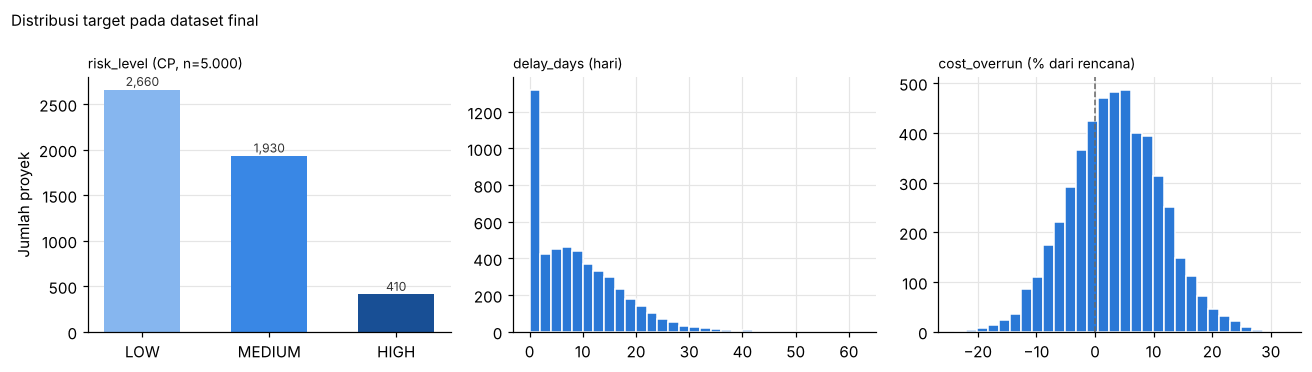

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
vc = final.risk_level.value_counts().reindex(["LOW", "MEDIUM", "HIGH"])
axes[0].bar(vc.index, vc.values, color=[C_ORD[k] for k in vc.index], width=0.6)
for i, v in enumerate(vc.values): axes[0].text(i, v + 40, f"{v:,}", ha="center", fontsize=8, color="#333")
axes[0].set_title("risk_level (CP, n=5.000)", loc="left", fontsize=9); axes[0].grid(axis="x", visible=False)
axes[1].hist(final.delay_days.dropna().astype(float), bins=np.arange(0, 64, 2), color=C_MAIN, edgecolor="white", linewidth=1)
axes[1].set_title("delay_days (hari)", loc="left", fontsize=9)
axes[2].hist(final.cost_overrun.dropna().astype(float) * 100, bins=30, color=C_MAIN, edgecolor="white", linewidth=1)
axes[2].axvline(0, color="#666", lw=1, ls="--")
axes[2].set_title("cost_overrun (% dari rencana)", loc="left", fontsize=9)
axes[0].set_ylabel("Jumlah proyek")
fig.suptitle("Distribusi target pada dataset final", x=0.01, ha="left", fontsize=10)
plt.tight_layout(); plt.show()

In [16]:
# 8. Missing values setelah harmonisasi (per sumber, %)
miss = final.drop(columns=TRACKING).isna().groupby(final.source_dataset).mean().T.mul(100).round(1)
miss["semua_sumber_%"] = final.drop(columns=TRACKING).isna().mean().mul(100).round(1)
display(miss.sort_values("semua_sumber_%"))

source_dataset                 CONSTRUCTION_DELAY_PRED_ALG  CONSTRUCTION_DELAY_RISK_GH  semua_sumber_%
flag_kendala_material                                  0.0                         0.0             0.0
flag_kendala_keselamatan                               0.0                         0.0             0.0
kondisi_pekerjaan                                      0.0                         0.0             0.0
jumlah_insiden_keselamatan                             0.0                         0.0             0.0
jumlah_pekerja                                         0.0                         0.0             0.0
progress_persen                                        0.0                         0.0             0.0
estimasi_biaya                                         0.0                         0.0             0.0
mata_uang                                              0.0                         0.0             0.0
has_target_cost                                        0.0               

## 11. Data pendukung terpisah: survei Aceh → bobot faktor per kategori

Data survei **tidak** masuk ke dataset training. Data ini diolah menjadi tabel referensi untuk `checklist_factors`:
- statistik skor pengaruh per item (rata-rata, median, persentase skor 4–5);
- pemetaan **per item** (bukan per kelompok) ke kategori standar Way2Home.

Pemetaan dibuat per item karena satu kelompok bisa berisi beberapa makna. Contohnya, kelompok *Environment* memuat cuaca, keselamatan, dan geologi.

In [17]:
# Header Aceh sudah terdeteksi otomatis; pastikan bentuknya
aceh = aceh_raw.copy()
aceh.columns = [str(c) for c in aceh.columns]
id_col = [c for c in aceh.columns if "Responden" in c][0]
aceh = aceh.rename(columns={id_col: "responden_id"}).apply(pd.to_numeric, errors="coerce")
item_cols = [c for c in aceh.columns if c.startswith("X")]
assert aceh[item_cols].isna().sum().sum() == 0 and aceh[item_cols].isin([1, 2, 3, 4, 5]).all().all()

ACEH_ITEMS = {  # (label artikel PLOS ONE 2022, kategori standar Way2Home)
 "X1.1": ("Lack of construction materials", "MATERIAL"), "X1.2": ("Material changes in form, function and specifications", "MATERIAL"),
 "X1.3": ("Material delivery delay", "MATERIAL"), "X1.4": ("Material damage in storage", "MATERIAL"),
 "X1.5": ("Scarcity of materials", "MATERIAL"), "X1.6": ("Inaccuracy in ordering materials", "MATERIAL"),
 "X1.7": ("Inefficient use of materials", "MATERIAL"), "X1.8": ("Delayed material arrival", "MATERIAL"),
 "X1.9": ("Poor calculation of material requirements", "MATERIAL"),
 "X2.1": ("Equipment breakdown", "PERALATAN"), "X2.2": ("Lack of equipment", "PERALATAN"), "X2.3": ("Poor equipment productivity", "PERALATAN"),
 "X3.1": ("Poor financial condition during implementation", "KEUANGAN"), "X3.2": ("Delay in the payment process by the owner", "KEUANGAN"),
 "X3.3": ("No financial support from banks for additional working capital", "KEUANGAN"), "X3.4": ("High operational costs and overhead by contractors", "KEUANGAN"),
 "X4.1": ("Effect of weather on construction activities", "CUACA"), "X4.2": ("Poor environmental safety", "KESELAMATAN"),
 "X4.3": ("Geological problems on site", "LAINNYA"), "X4.4": ("Lack of communication between contractors and the community", "LAINNYA"),
 "X4.5": ("Difficult access for heavy equipment to the project site", "LAINNYA"),
 "X5.1": ("Shortage of labour", "TENAGA_KERJA"), "X5.2": ("Labour incapacity", "TENAGA_KERJA"), "X5.3": ("Owner's intervention", "MANAJEMEN"),
 "X5.4": ("Labour fatigue owing to overtime", "TENAGA_KERJA"), "X5.5": ("Lack of awareness of project workers on occupational safety and health", "KESELAMATAN"),
 "X5.6": ("Replacement of new workers", "TENAGA_KERJA"), "X5.7": ("Labour absenteeism rate", "TENAGA_KERJA"), "X5.8": ("Lack of workforce motivation", "TENAGA_KERJA"),
 "X6.1": ("Licensing delay", "LAINNYA"), "X6.2": ("There is a design change", "DESAIN"), "X6.3": ("Design errors by planners", "DESAIN"),
 "X6.4": ("There is additional work", "DESAIN"),
 "X7.1": ("Weak time control system", "PENGAWASAN"), "X7.2": ("The arrangement of the sequence of activities is not good", "MANAJEMEN"),
 "X7.3": ("No evaluation of job specifications before implementation", "MANAJEMEN"), "X7.4": ("There is no operating procedure for each job", "MANAJEMEN"),
 "X7.5": ("Error in understanding contract documents", "MANAJEMEN"), "X7.6": ("Poor occupational health and safety management", "KESELAMATAN"),
 "X7.7": ("Improper quality management procedures", "PENGAWASAN"), "X7.8": ("Error in using execution method", "MANAJEMEN"),
 "X8.1": ("Counterproductive news from print and electronic media", "LAINNYA"), "X8.2": ("Lack of coordination between relevant agencies in decision making", "LAINNYA"),
 "X8.3": ("Inputs from other agencies resulting in design and technical changes", "DESAIN"), "X8.4": ("Complicated permitting procedure by various parties", "LAINNYA"),
 "X8.5": ("Delay in the approval of the budget", "KEUANGAN"), "X8.6": ("Rejection from certain mass organisations", "LAINNYA"),
 "X9.1": ("Loss of materials and equipment during project implementation", "LAINNYA"), "X9.2": ("Damage to tools, materials and facilities by irresponsible parties", "LAINNYA"),
 "X9.3": ("Petty corruption practices by project workers", "LAINNYA"), "X9.4": ("Use of illegal substances and drugs by workers", "TENAGA_KERJA"),
 "X9.5": ("Extortion from outside", "LAINNYA"), "X9.6": ("Fights between workers", "TENAGA_KERJA"),
 "X10.1": ("Poor ability of the PM in selecting personnel", "MANAJEMEN"), "X10.2": ("Lack of PM experience in dividing tasks and responsibilities", "MANAJEMEN"),
 "X10.3": ("Lack of PM experience in scheduling all work activities", "MANAJEMEN"), "X10.4": ("Lack of PM communication skills with the owner", "MANAJEMEN"),
 "X10.5": ("Poor communication between the PM and his team, including sub-contractors", "MANAJEMEN"),
 "X10.6": ("PM does not encourage the whole team to work in totality", "MANAJEMEN"),
 "X10.7": ("Lack of monitoring and control during project implementation", "PENGAWASAN"),
}
ACEH_GROUPS = {"X1": "Material", "X2": "Equipment", "X3": "Financial", "X4": "Environment", "X5": "Labour",
               "X6": "Implementation", "X7": "Management", "X8": "Political", "X9": "Criminal", "X10": "Project Manager"}
assert set(item_cols) == set(ACEH_ITEMS)

aceh_items = pd.DataFrame({
    "kode_item": item_cols,
    "kelompok_asli": [ACEH_GROUPS[c.split(".")[0]] for c in item_cols],
    "faktor": [ACEH_ITEMS[c][0] for c in item_cols],
    "kategori_way2home": [ACEH_ITEMS[c][1] for c in item_cols],
    "n_responden": len(aceh),
    "mean_skor": aceh[item_cols].mean().round(3).values,
    "median_skor": aceh[item_cols].median().values,
    "sd_skor": aceh[item_cols].std().round(3).values,
    "persen_skor_4_5": (aceh[item_cols] >= 4).mean().mul(100).round(1).values,
})
aceh_items["peringkat_global"] = aceh_items["mean_skor"].rank(ascending=False, method="min").astype(int)
aceh_items["sumber"] = "Rauzana & Dharma (2022) PLOS ONE 17(1):e0263337; Mendeley 10.17632/2wckhrzz5j.1"
aceh_items["skala"] = "Likert 1-5 tingkat pengaruh terhadap keterlambatan (persepsi PM, bukan kejadian)"
aceh_kat = (aceh_items.groupby("kategori_way2home")
            .agg(n_item=("kode_item", "size"), mean_skor=("mean_skor", "mean"), faktor_teratas=("faktor", "first"))
            .round(3).sort_values("mean_skor", ascending=False))
# faktor teratas per kategori = item dengan mean tertinggi
aceh_kat["faktor_teratas"] = aceh_items.sort_values("mean_skor", ascending=False).groupby("kategori_way2home").faktor.first()
display(aceh_kat)

# Simpan versi long (responden x item) sebagai data survei yang telah dibersihkan
aceh_long = aceh.melt(id_vars="responden_id", value_vars=item_cols + [c for c in aceh.columns if c.startswith("Y")],
                      var_name="kode_item", value_name="skor")
aceh_long["source_dataset"] = "ACEH_DELAY_SURVEY"; aceh_long["data_granularity"] = "survey"; aceh_long["is_synthetic"] = False
print("Y1–Y4: UNRESOLVED — maknanya tidak terdokumentasi; disimpan apa adanya, tidak dipakai sebagai target.")

                   n_item  mean_skor                                                          faktor_teratas
kategori_way2home                                                                                           
KEUANGAN                5      4.635                                     Delay in the approval of the budget
DESAIN                  4      4.599                                               Design errors by planners
PERALATAN               3      4.549                                                     Equipment breakdown
MATERIAL                9      4.422                                              Material damage in storage
KESELAMATAN             3      4.382  Lack of awareness of project workers on occupational safety and health
CUACA                   1      4.353                            Effect of weather on construction activities
PENGAWASAN              3      4.294            Lack of monitoring and control during project implementation
TENAGA_KERJA       

## 12. Penyimpanan semua output & laporan

In [18]:
# ---------- Dataset final & subset ----------
final.to_csv(FINAL / "way2home_kendala_training.csv", index=False)
risk_df.to_csv(FINAL / "way2home_risk_classification.csv", index=False)
delay_df.to_csv(FINAL / "way2home_delay_regression.csv", index=False)
cost_df.to_csv(FINAL / "way2home_cost_prediction.csv", index=False)
dbin_df.to_csv(FINAL / "way2home_delay_risk_binary.csv", index=False)

# ---------- Data pendukung ----------
aceh_items.to_csv(PROC / "aceh_factor_importance.csv", index=False)
aceh_kat.reset_index().to_csv(PROC / "aceh_category_importance.csv", index=False)
aceh_long.to_csv(PROC / "aceh_survey_clean_long.csv", index=False)
cp.to_csv(PROC / "construction_delay_risk_gh_clean.csv", index=False)
alg.to_csv(PROC / "construction_delay_pred_alg_clean.csv", index=False)
evs.to_csv(PROC / "sim_ev_summary_parsed_EXCLUDED.csv", index=False)   # diparse untuk referensi, tidak dipakai

# ---------- data_dictionary.csv ----------
derived_rows = [
 ("record_uid", "(dibuat)", "ID unik baris dataset final", "string", "-", "W2H_ + nomor urut", "tracking", "-"),
 ("source_dataset", "(dibuat)", "Kode sumber dataset", "string", "-", "dari identifikasi signature kolom", "tracking (bukan fitur)", "-"),
 ("project_group_id", "(dibuat)", "ID grup proyek untuk group-based split", "string", "-", "source_dataset::source_record_id", "tracking (bukan fitur)", "-"),
 ("data_granularity", "(dibuat)", "Granularitas record", "string", "-", "'project' untuk semua baris final", "tracking (bukan fitur)", "-"),
 ("is_synthetic", "(dibuat)", "Penanda data sintetis", "bool", "-", "berdasarkan dokumentasi + bukti audit", "tracking (bukan fitur)", "-"),
 ("kategori", "(turunan flag)", "Kategori kendala tercatat (multi-label, dipisah '|', urut dampak hari terbesar)", "string", "kategori standar", "dari flag_kendala_*; null jika tidak ada kendala tercatat", "tidak langsung (pakai flag_kendala_*)", "kategori"),
 ("flag_kendala_material", "material_delay_days>0 (CP); Supplier_Delay=Yes atau Material_Availability=Low (ALG)", "Ada kendala material/pengadaan", "Int8", "0/1", "lihat kolom_asli", "ya", "kategori = MATERIAL"),
 ("flag_kendala_cuaca", "weather_delay_days>0 (CP)", "Ada kendala cuaca (kejadian)", "Int8", "0/1", "ALG null: Weather_Risk = paparan, bukan kejadian", "ya", "kategori = CUACA"),
 ("flag_kendala_peralatan", "Equipment_Availability=Low (ALG)", "Ada kendala ketersediaan peralatan", "Int8", "0/1", "CP null: tidak ada kejadian kendala alat", "ya", "kategori = PERALATAN"),
 ("flag_kendala_keselamatan", "safety_incidents>0 / Safety_Incidents>0", "Ada insiden keselamatan", "Int8", "0/1", "> 0 -> 1", "ya", "kategori = KESELAMATAN"),
 ("dampak_waktu_hari", "material_delay_days + weather_delay_days (CP)", "Total hari dampak kendala tercatat", "Int64", "hari", "penjumlahan; null jika komponen tidak lengkap", "ya", "dampak_waktu_hari"),
 ("kondisi_pekerjaan", "(tidak ada di sumber)", "Kondisi pekerjaan", "string", "BERHENTI/TERHAMBAT_SEBAGIAN/NORMAL/UNKNOWN", "UNKNOWN untuk semua (tidak diisi NORMAL)", "tidak (konstan)", "kondisi_pekerjaan"),
 ("delay_ratio", "-", "delay_days / durasi_rencana_hari", "Float64", "rasio", "TIDAK dihitung: CP durasi rencana UNRESOLVED, ALG tanpa delay_days", "tidak (null)", "-"),
 ("cost_overrun_ratio", "actual_cost, project_budget (CP)", "(aktual - rencana) / rencana", "Float64", "rasio", "dihitung jika keduanya ada & rencana > 0", "tidak (outcome)", "-"),
 ("progress_gap", "-", "progress aktual - progress rencana", "Float64", "% poin", "TIDAK dihitung: progress rencana tidak tersedia", "tidak (null)", "-"),
 ("cost_progress_gap_persen", "Cost_Used_Percent - Project_Progress_Percent (ALG)", "Selisih % biaya terpakai vs % progres", "Float64", "% poin", "dihitung jika keduanya ada", "ya", "metrics.overbudget_risk (indikator)"),
 ("cost_overrun", "cost_overrun_ratio", "TARGET: rasio pembengkakan biaya", "Float64", "rasio", "= cost_overrun_ratio (CP)", "TARGET", "metrics.overbudget_risk / cost_notes"),
 ("overbudget_flag", "cost_overrun", "TARGET alternatif: 1 jika cost_overrun > 0", "Int8", "0/1", "cost_overrun > 0", "TARGET", "metrics.overbudget_risk"),
 ("mata_uang", "(dibuat)", "Mata uang kolom biaya", "string", "-", "CP=UNKNOWN, ALG=DZD", "tidak (proxy sumber)", "-"),
 ("has_target_risk/delay/cost/delay_binary", "(dibuat)", "Indikator ketersediaan target per tugas", "Int8", "0/1", "target notna", "tidak (meta)", "-"),
 ("outlier_flags", "(dibuat)", "Daftar kolom yang ekstrem (IQR x 3 per sumber)", "string", "-", "tidak menghapus data", "tidak (meta)", "-"),
 ("deskripsi / informasi_tambahan / judul_subtask / nama_tahap / nama_desain", "(tidak ada di sumber)", "Teks & struktur tahap Way2Home", "string", "-", "null — tidak ada padanan", "tidak (null)", "nama yang sama"),
 ("bobot_subtask", "(tidak ada di sumber)", "Bobot subtask", "Float64", "-", "null — tidak ada padanan", "tidak (null)", "bobot_subtask"),
 ("status_proyek", "(tidak ada di sumber)", "Status proyek Way2Home", "string", "-", "null — UNRESOLVED: enum Way2Home belum diketahui; progress_persen tersedia sebagai proxy", "tidak (null)", "status_proyek"),
 ("labor_availability_status / kondisi_cuaca / durasi_aktual_hari", "(tidak ada di sumber)", "-", "-", "-", "null — tidak ada padanan", "tidak (null)", "-"),
]
dd_derived = pd.DataFrame(derived_rows, columns=["kolom_standar", "kolom_asli", "makna", "tipe_data", "satuan",
                                                 "aturan_transformasi", "layak_training", "padanan_input_way2home"])
dd_derived["source_dataset"] = "SEMUA / TURUNAN"
data_dictionary = pd.concat([CM, dd_derived], ignore_index=True)[
    ["kolom_standar", "source_dataset", "kolom_asli", "makna", "tipe_data", "satuan", "aturan_transformasi",
     "layak_training", "padanan_input_way2home"]]
data_dictionary["dipakai_di_subset"] = data_dictionary.kolom_standar.map(lambda c: ", ".join(
    n for n, f in [("risk", risk_feats), ("delay", delay_feats), ("cost", cost_feats), ("delay_binary", dbin_feats)] if c in f) or "-")
data_dictionary.to_csv(PROC / "data_dictionary.csv", index=False)

# ---------- source_mapping_report.csv ----------
DECISION = {
 "CONSTRUCTION_DELAY_RISK_GH": ("MASUK_FINAL", "risk_level, delay_days, cost_overrun", "Project-level konstruksi dengan outcome delay & biaya; label risk berbasis outcome (ambang delay_days); delay_days dilarang sebagai fitur risk."),
 "CONSTRUCTION_DELAY_PRED_ALG": ("MASUK_FINAL", "delay_risk_binary", "Project-level konstruksi; target biner tidak dipetakan ke 3 kelas; tidak ada delay_days/biaya aktual."),
 "ACEH_DELAY_SURVEY": ("PENDUKUNG_TERPISAH", "-", "Survey-level persepsi; tidak valid diubah jadi kejadian/label risiko; diolah menjadi bobot faktor per kategori (aceh_factor_importance.csv)."),
 "SIM_PROJECT_RISK_RAW": ("DIKELUARKAN", "-", f"{evidence['RAW_share_non_construction']:.0%} non-konstruksi; definisi Risk_Level tidak terdokumentasi; kelas {evidence['RAW_risk_classes']}; fitur manajerial tanpa padanan Way2Home."),
 "SIM_EV_SUMMARY": ("DIKELUARKAN", "-", f"Turunan SIM_PROJECT_RISK_RAW (budget match {evidence['EV_from_raw_budget_match']:.0%}); target = rumus fitur + noise (sirkular); bug encoding (Critical/Mixed/Expert/Basic/Excellent -> 0)."),
 "SIM_EV_TIMESERIES": ("DIKELUARKAN", "-", "Deret waktu bulanan turunan simulasi yang sama; granularitas project-month."),
 "BIM_AI_CIVIL": ("DIKELUARKAN", "-", f"Risk_Level direproduksi {evidence['BIM_label_rule_reproduction']:.1%} oleh aturan Safety_Risk_Score+Anomaly; rasio biaya seragam (KS p={evidence['BIM_cost_ratio_uniform_KS_p']:.2f}) & independen dari fitur; End_Date tidak konsisten."),
 "RCPLIB_BENCHMARK": ("DIKELUARKAN", "-", "Instance RCPSP buatan generator (bukan DSLIB empiris); tidak ada outcome delay/biaya proyek nyata."),
}
n_final = final.source_dataset.value_counts()
smr = inventory.copy()
smr["judul"] = smr.source_dataset.map(lambda s: SOURCE_META[s]["title"])
smr["bukti_sintetis_empiris"] = smr.source_dataset.map(lambda s: SOURCE_META[s]["evidence"])
smr["keputusan"] = smr.source_dataset.map(lambda s: DECISION[s][0])
smr["target_disumbangkan"] = smr.source_dataset.map(lambda s: DECISION[s][1])
smr["alasan"] = smr.source_dataset.map(lambda s: DECISION[s][2])
smr["n_records_final"] = smr.source_dataset.map(n_final).fillna(0).astype(int)
smr.loc[smr.source_dataset == "ACEH_DELAY_SURVEY", "n_records_final"] = 0
smr["n_records_pendukung"] = np.where(smr.source_dataset == "ACEH_DELAY_SURVEY", len(aceh_items), 0)
smr.to_csv(PROC / "source_mapping_report.csv", index=False)

# ---------- excluded_records_report.csv ----------
excl = []
for _, r in smr.iterrows():
    if r.keputusan != "MASUK_FINAL":
        excl.append({"source_dataset": r.source_dataset, "level": "seluruh sumber", "source_record_id": "*",
                     "n_records": r.n_records_raw, "reason": r.alasan,
                     "status": "dipakai sebagai data pendukung" if r.keputusan == "PENDUKUNG_TERPISAH" else "tidak dipakai"})
for e in excluded_rows:
    excl.append({**e, "level": "record", "n_records": 1, "status": "tidak dipakai"})
excluded_report = pd.DataFrame(excl)
excluded_report.to_csv(PROC / "excluded_records_report.csv", index=False)

# ---------- data_quality_report.csv ----------
dq = []
for c in FINAL_COLUMNS:
    s = final[c]
    num = pd.to_numeric(s, errors="coerce") if str(s.dtype) in ("Int64", "Int8", "Float64") else None
    dq.append({"bagian": "kolom", "item": c, "dtype": str(s.dtype), "n_non_null": int(s.notna().sum()),
               "missing_%": round(s.isna().mean() * 100, 1),
               "missing_%_CP": round(s[final.source_dataset == "CONSTRUCTION_DELAY_RISK_GH"].isna().mean() * 100, 1),
               "missing_%_ALG": round(s[final.source_dataset == "CONSTRUCTION_DELAY_PRED_ALG"].isna().mean() * 100, 1),
               "n_unique": int(s.nunique()), "min": None if num is None else num.min(), "max": None if num is None else num.max(),
               "n_outlier_rows": int(final.outlier_flags.fillna("").str.split("|").apply(lambda l: c in l).sum()),
               "status": "UNRESOLVED/tanpa padanan" if s.isna().all() else ""})
for _, r in checks_df.iterrows():
    dq.append({"bagian": "validasi", "item": r.cek, "status": r.status, "dtype": "", "detail": r.detail})
for _, r in leak_tbl.iterrows():
    dq.append({"bagian": "leakage_fitur_tunggal", "item": r.subset, "status": f"{r.fitur_terkuat}: {r.metrik}={r.skor_fitur_tunggal}"})
for k, v in evidence.items():
    dq.append({"bagian": "bukti_keputusan_sumber", "item": k, "status": str(v)})
UNRESOLVED = [
 ("Mata uang biaya CP tidak terdokumentasi", "Biaya absolut tidak bisa dibandingkan lintas sumber; dipakai rasio. Konversi DZD/IDR tidak dilakukan (asumsi kurs)."),
 ("project_duration_days CP: rencana atau aktual?", "delay_ratio tidak dihitung; durasi disimpan di kolom netral durasi_proyek_hari."),
 ("actual_cost CP pada proyek progres < 100%", "Belum pasti biaya final; target cost_overrun valid secara definisi namun lemah secara sinyal."),
 ("Enum kategori & status_proyek Way2Home belum diterima", "status_proyek null; kategori memakai daftar standar dari brief."),
 ("Arti Y1–Y4 survei Aceh", "Disimpan apa adanya di aceh_survey_clean_long.csv; tidak dipakai."),
 ("Tidak ada data empiris dengan outcome", "Validasi empiris vs sintetis untuk model tidak dapat dilakukan; semua baris final sintetis."),
]
for k, v in UNRESOLVED:
    dq.append({"bagian": "UNRESOLVED", "item": k, "status": v})
data_quality = pd.DataFrame(dq)
data_quality.to_csv(PROC / "data_quality_report.csv", index=False)

# ---------- ringkasan JSON (untuk model_metadata nanti) ----------
summary = {
  "final_file": "data/final/way2home_kendala_training.csv", "shape": list(final.shape),
  "unit_observasi": "project", "records_by_source": final.source_dataset.value_counts().to_dict(),
  "synthetic_records": int(final.is_synthetic.sum()), "empirical_records": int((~final.is_synthetic).sum()),
  "subsets": {"risk_classification": {"rows": len(risk_df), "features": risk_feats, "target": "risk_level"},
              "delay_regression": {"rows": len(delay_df), "features": delay_feats, "target": "delay_days"},
              "cost_prediction": {"rows": len(cost_df), "features": cost_feats, "target": ["cost_overrun", "overbudget_flag"]},
              "delay_risk_binary": {"rows": len(dbin_df), "features": dbin_feats, "target": "delay_risk_binary"}},
  "group_column": "meta_project_group_id",
  "excluded_sources": {k: v[2] for k, v in DECISION.items() if v[0] == "DIKELUARKAN"},
  "unresolved": dict(UNRESOLVED),
}
json.dump(summary, open(PROC / "harmonization_summary.json", "w"), indent=2, ensure_ascii=False, default=str)

for p in sorted(list(FINAL.glob("*.csv")) + list(PROC.glob("*"))):
    print(f"{str(p.relative_to(ROOT)):60s} {p.stat().st_size/1024:9.1f} KB")

data/final/way2home_cost_prediction.csv                          763.8 KB
data/final/way2home_delay_regression.csv                         665.3 KB
data/final/way2home_delay_risk_binary.csv                        176.0 KB
data/final/way2home_kendala_training.csv                        1658.6 KB
data/final/way2home_risk_classification.csv                      679.3 KB
data/processed/aceh_category_importance.csv                        0.6 KB
data/processed/aceh_factor_importance.csv                         15.1 KB
data/processed/aceh_survey_clean_long.csv                        173.7 KB
data/processed/construction_delay_pred_alg_clean.csv             194.2 KB
data/processed/construction_delay_risk_gh_clean.csv             1130.4 KB
data/processed/data_dictionary.csv                                 9.3 KB
data/processed/data_quality_report.csv                             7.8 KB
data/processed/excluded_records_report.csv                         1.1 KB
data/processed/harmonization_summary.j

## 13. Ringkasan akhir

In [19]:
print("LOKASI FILE FINAL :", (FINAL / "way2home_kendala_training.csv").relative_to(ROOT))
print("UKURAN            :", f"{final.shape[0]:,} baris × {final.shape[1]} kolom")
print("\nPERBANDINGAN JUMLAH RECORD SEBELUM vs SESUDAH PREPROCESSING")
cmp = smr[["source_dataset", "granularity", "n_records_raw", "keputusan", "n_records_final", "n_records_pendukung"]]
display(cmp)
print(f"Total record mentah (semua tabel): {int(smr.n_records_raw.sum()):,} -> baris dataset final: {len(final):,}")

LOKASI FILE FINAL : data/final/way2home_kendala_training.csv
UKURAN            : 6,000 baris × 57 kolom

PERBANDINGAN JUMLAH RECORD SEBELUM vs SESUDAH PREPROCESSING
                source_dataset          granularity  n_records_raw           keputusan  n_records_final  n_records_pendukung
0            ACEH_DELAY_SURVEY               survey             68  PENDUKUNG_TERPISAH                0                   60
1                 BIM_AI_CIVIL              project           1000         DIKELUARKAN                0                    0
2  CONSTRUCTION_DELAY_PRED_ALG              project           1000         MASUK_FINAL             1000                    0
3   CONSTRUCTION_DELAY_RISK_GH              project           5000         MASUK_FINAL             5000                    0
4             RCPLIB_BENCHMARK  scheduling-instance          13574         DIKELUARKAN                0                    0
5               SIM_EV_SUMMARY              project           4000         DIKELUARKA

In [20]:
all_feats = sorted(set(risk_feats) | set(delay_feats) | set(cost_feats) | set(dbin_feats))
print("FITUR (dipakai di minimal satu subset):", all_feats)
print("TARGET:", TARGETS)
print("\nJUMLAH RECORD PER SUMBER:"); display(final.source_dataset.value_counts())
print("KOMPOSISI EMPIRIS/SINTETIS (dataset final):", final.is_synthetic.map({True: "sintetis", False: "empiris"}).value_counts().to_dict(),
      "| data empiris pendukung: survei Aceh 68 responden (tidak masuk training)")
print("\nDISTRIBUSI LABEL:")
print("  risk_level        :", final.risk_level.value_counts().to_dict())
print("  delay_risk_binary :", final.delay_risk_binary.value_counts().to_dict())
print("  overbudget_flag   :", final.overbudget_flag.value_counts().to_dict())
print(f"  delay_days        : median {final.delay_days.median():.0f} hari, mean {final.delay_days.astype(float).mean():.2f}, max {final.delay_days.max()}")
print(f"  cost_overrun      : median {final.cost_overrun.astype(float).median():.3f}, rentang {final.cost_overrun.min():.3f} s/d {final.cost_overrun.max():.3f}")
mv = final.drop(columns=TRACKING).isna().mean().mul(100).round(1)
print("\nKOLOM MASIH MEMILIKI MISSING (%):"); display(mv[mv > 0].sort_values(ascending=False))
print("SUMBER YANG TIDAK DIGABUNG:")
for k, v in DECISION.items():
    if v[0] != "MASUK_FINAL":
        print(f"  - {k} [{v[0]}]: {v[2]}")

FITUR (dipakai di minimal satu subset): ['biaya_terpakai_persen', 'cost_progress_gap_persen', 'dampak_waktu_cuaca_hari', 'dampak_waktu_hari', 'dampak_waktu_material_hari', 'durasi_proyek_hari', 'durasi_rencana_hari', 'equipment_availability_status', 'estimasi_biaya', 'flag_kendala_cuaca', 'flag_kendala_keselamatan', 'flag_kendala_material', 'flag_kendala_peralatan', 'jenis_proyek', 'jumlah_insiden_keselamatan', 'jumlah_pekerja', 'keterlambatan_pemasok', 'kompleksitas_proyek', 'material_availability_status', 'progress_persen', 'risiko_cuaca', 'utilisasi_peralatan_persen']
TARGET: ['risk_level', 'delay_days', 'cost_overrun', 'overbudget_flag', 'delay_risk_binary']

JUMLAH RECORD PER SUMBER:
source_dataset
CONSTRUCTION_DELAY_RISK_GH     5000
CONSTRUCTION_DELAY_PRED_ALG    1000
KOMPOSISI EMPIRIS/SINTETIS (dataset final): {'sintetis': 6000} | data empiris pendukung: survei Aceh 68 responden (tidak masuk training)

DISTRIBUSI LABEL:
  risk_level        : {'LOW': 2660, 'MEDIUM': 1930, 'HIGH':

### Rekomendasi kelayakan training

**Layak untuk eksperimen/skripsi, belum layak untuk produksi.**

1. **`risk_level` & `delay_days`** (5.000 baris CP) dapat dilatih dengan *group split* pada `meta_project_group_id`. Sinyalnya sedang (audit: macro-F1 ≈ 0,6; R² ≈ 0,54). HIGH hanya 8,2%, jadi gunakan `class_weight` dan macro-F1.
2. **`cost_overrun`** dapat dilatih sebagai eksperimen, tetapi sinyalnya ≈ 0. Hasilnya harus dilaporkan sebagai *negative result*, dan `metrics.overbudget_risk` di service tetap memakai logika yang ada.
3. **`delay_risk_binary`** (1.000 baris ALG) adalah tugas pendamping untuk menguji konsistensi faktor material/alat/pemasok/cuaca.
4. **Seluruh baris final sintetis.** Validasi empiris vs sintetis untuk performa model tidak bisa dilakukan. Survei Aceh hanya mendukung `checklist_factors`, bukan metrik akurasi.
5. Fitur yang **setara input Way2Home** hanya `flag_kendala_*`, `dampak_waktu_*`, dan `progress_persen`. Kolom teks (`deskripsi`, `kondisi_pekerjaan`, `informasi_tambahan`, `judul_subtask`) serta `nama_tahap`, `bobot_subtask`, dan `nama_desain` belum punya data latih.
6. **Data tambahan yang paling dibutuhkan:** riwayat kendala Way2Home di Supabase beserta outcome aktual (hari keterlambatan, biaya), serta DSLIB empiris (baseline vs aktual) bila ingin outcome proyek nyata.